In [6]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from ml_security import ChallengeClient
from ml_security.utils import load_image, save_image

In [7]:
client = ChallengeClient.from_env()

run_dir = Path("notebook_runs/challenge2_detection")
images_dir = run_dir / "images"
masks_dir = run_dir / "masks"

run_dir.mkdir(parents=True, exist_ok=True)
images_dir.mkdir(parents=True, exist_ok=True)
masks_dir.mkdir(parents=True, exist_ok=True)

print(f"Images will be saved to: {images_dir}")
print(f"Masks will be saved to:  {masks_dir}")

Images will be saved to: notebook_runs/challenge2_detection/images
Masks will be saved to:  notebook_runs/challenge2_detection/masks


In [8]:
image_list = client.list_images()

active_images = [img for img in image_list if img.get("is_active", True)]

print(f"Total images available: {len(image_list)}")
print(f"Active images:          {len(active_images)}")
print()
print("First 10 entries:")
for entry in active_images[:10]:
    print(f"  {entry}")

Total images available: 10
Active images:          10

First 10 entries:
  {'image_id': 'img_0006', 'is_active': True}
  {'image_id': 'img_0024', 'is_active': True}
  {'image_id': 'img_0051', 'is_active': True}
  {'image_id': 'img_0070', 'is_active': True}
  {'image_id': 'img_0073', 'is_active': True}
  {'image_id': 'img_0104', 'is_active': True}
  {'image_id': 'img_0157', 'is_active': True}
  {'image_id': 'img_0176', 'is_active': True}
  {'image_id': 'img_0188', 'is_active': True}
  {'image_id': 'img_0192', 'is_active': True}


In [9]:
downloaded: list[dict] = []

for entry in active_images:
    image_id = entry["image_id"]
    save_path = images_dir / f"{image_id}.png"

    if save_path.exists():
        print(f"[skip]     {image_id}  (already on disk)")
    else:
        client.download_image(image_id, str(save_path))
        print(f"[download] {image_id}")

    downloaded.append({"image_id": image_id, "path": save_path})

print(f"\nTotal images on disk: {len(downloaded)}")

[download] img_0006
[download] img_0024
[download] img_0051
[download] img_0070
[download] img_0073
[download] img_0104
[download] img_0157
[download] img_0176
[download] img_0188
[download] img_0192

Total images on disk: 10


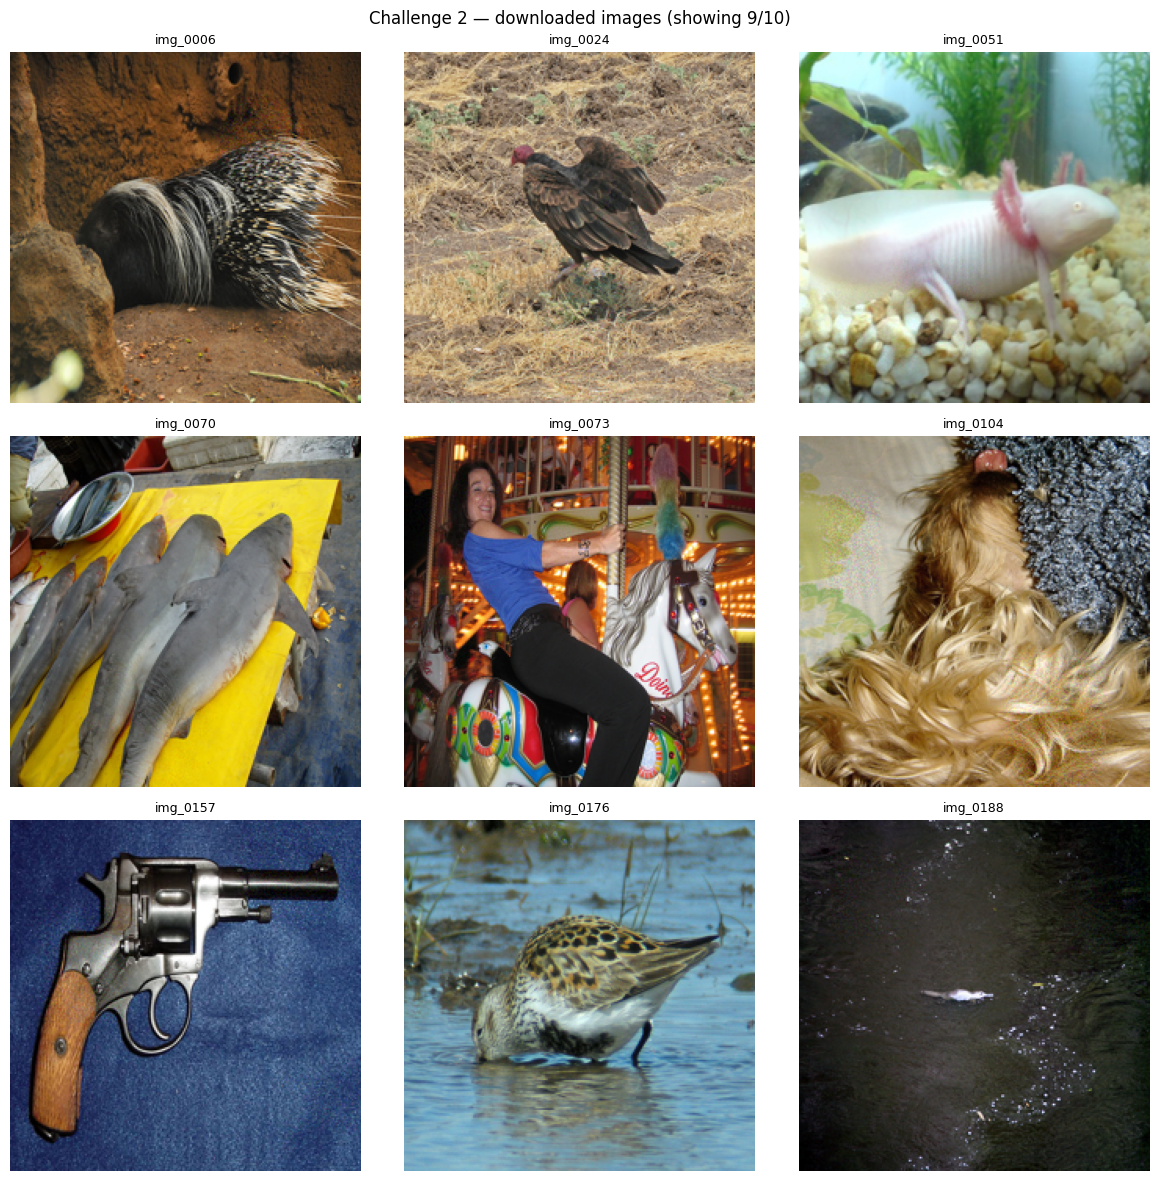

In [10]:
n_show = min(9, len(downloaded))
ncols = 3
nrows = (n_show + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
axes = np.array(axes).reshape(-1)

for i, ax in enumerate(axes):
    if i < n_show:
        entry = downloaded[i]
        img = load_image(str(entry["path"]))
        ax.imshow(img)
        ax.set_title(entry["image_id"], fontsize=9)
    ax.axis("off")

plt.suptitle(f"Challenge 2 — downloaded images (showing {n_show}/{len(downloaded)})", fontsize=12)
plt.tight_layout()
plt.show()

image_id : img_0051
shape    : (224, 224, 3)
dtype    : uint8
min/max  : 2 / 255


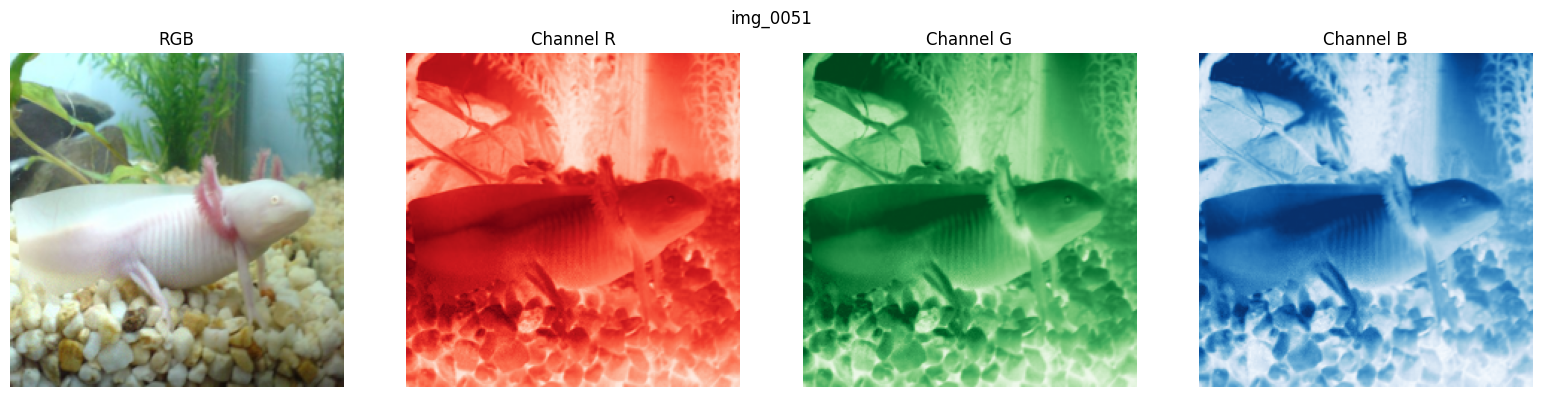

In [13]:
# Pick one image and inspect it more closely before deciding on a detection strategy
sample = downloaded[2]
img_array = load_image(str(sample["path"]))

print(f"image_id : {sample['image_id']}")
print(f"shape    : {img_array.shape}")
print(f"dtype    : {img_array.dtype}")
print(f"min/max  : {img_array.min()} / {img_array.max()}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(img_array)
axes[0].set_title("RGB")
axes[0].axis("off")

for ch, (label, color) in enumerate(zip(("R", "G", "B"), ("Reds", "Greens", "Blues"))):
    axes[ch + 1].imshow(img_array[:, :, ch], cmap=color, vmin=0, vmax=255)
    axes[ch + 1].set_title(f"Channel {label}")
    axes[ch + 1].axis("off")

plt.suptitle(sample["image_id"])
plt.tight_layout()
plt.show()